# 01 · Data and sessionization

What the export looks like, what the dry run reports before each query, and the session- and
user-level tables built by `sql/`. The data is **synthetic** with the GA4 export schema
(see `docs/DATA.md`).

In [1]:
import pandas as pd

from ga4_analytics.db import Warehouse
from ga4_analytics.plots import save, use_style

use_style()
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
wh = Warehouse()

## Dry run before every query

The runner validates the plan, applies the pushed-down `_TABLE_SUFFIX` filter to find which daily
files survive, and sums the compressed bytes of only the columns the query reads.

In [2]:
one_day = """
SELECT event_name, count(*) AS events
FROM events
WHERE _TABLE_SUFFIX = '20201215'
GROUP BY 1 ORDER BY 2 DESC
"""
print(wh.dry_run(one_day).summary())
wh.query(one_day, dry_run=False)

dry run OK | 3.5 KB from 1 daily file(s) [20201215..20201215], columns: event_name


,event_name,events
0,page_view,7326
1,session_start,2025
2,view_item,1447
3,first_visit,1203
4,add_to_cart,289
5,begin_checkout,159
6,add_shipping_info,115
7,add_payment_info,81
8,purchase,33


In [3]:
whole_window = """
SELECT event_name, count(*) AS events, count(DISTINCT user_pseudo_id) AS users
FROM events
WHERE _TABLE_SUFFIX BETWEEN $start_suffix AND $end_suffix
GROUP BY 1 ORDER BY 2 DESC
"""
wh.query(whole_window)

dry run OK | 2.7 MB from 92 daily file(s) [20201101..20210131], columns: event_name, user_pseudo_id


,event_name,events,users
0,page_view,486101,80000
1,session_start,136427,79074
2,view_item,101044,46489
3,first_visit,80000,80000
4,add_to_cart,20783,18284
5,begin_checkout,12013,11090
6,add_shipping_info,8990,8481
7,add_payment_info,6761,6471
8,purchase,4299,4101


## Raw nested record

One purchase event as exported: `event_params` and `items` are arrays of structs, and session
source/medium lives in `event_params`, not in `traffic_source` (which is first touch).

In [4]:
raw = wh.query("""
SELECT event_name, user_pseudo_id, event_params, traffic_source, ecommerce, items
FROM events
WHERE _TABLE_SUFFIX = '20201214' AND event_name = 'purchase'
LIMIT 1
""")
for col in raw.columns:
    print(f"{col}: {raw.at[0, col]}\n")

dry run OK | 260.7 KB from 1 daily file(s) [20201214..20201214], columns: ecommerce, event_name, event_params, items, traffic_source, user_pseudo_id
event_name: purchase

user_pseudo_id: 3148583476.8927996394

event_params: [{'key': 'ga_session_id', 'value': {'string_value': None, 'int_value': 1607911486, 'float_value': None, 'double_value': None}}
 {'key': 'ga_session_number', 'value': {'string_value': None, 'int_value': 3, 'float_value': None, 'double_value': None}}
 {'key': 'engagement_time_msec', 'value': {'string_value': None, 'int_value': 3535, 'float_value': None, 'double_value': None}}]

traffic_source: {'name': 'remarketing', 'medium': 'cpm', 'source': 'google'}

ecommerce: {'total_item_quantity': 4, 'purchase_revenue_in_usd': None, 'purchase_revenue': 83.4, 'unique_items': 2, 'transaction_id': 'T0001012'}

items: [{'item_id': 'GGOE00070', 'item_name': 'Google Electronics Accessories Item 070', 'item_brand': 'Google', 'item_variant': '(not set)', 'item_category': 'Electronics 

## Modelled tables

In [5]:
counts = wh.query("""
SELECT 'events_flat' AS table_name, count(*) AS rows FROM events_flat UNION ALL
SELECT 'event_items', count(*) FROM event_items UNION ALL
SELECT 'transactions', count(*) FROM transactions UNION ALL
SELECT 'sessions', count(*) FROM sessions UNION ALL
SELECT 'users', count(*) FROM users UNION ALL
SELECT 'daily_kpis', count(*) FROM daily_kpis
""")
counts

dry run OK | no table reads


,table_name,rows
0,events_flat,856418
1,event_items,195563
2,transactions,4218
3,sessions,139187
4,users,80000
5,daily_kpis,92


In [6]:
wh.query("""
SELECT session_key, session_date, channel, device_category, user_type, page_views,
       funnel_depth, transactions, round(revenue_usd, 2) AS revenue_usd
FROM sessions
WHERE transactions > 0
ORDER BY session_start_ts
LIMIT 5
""")

dry run OK | local tables: ga4.main.sessions


,session_key,session_date,channel,device_category,user_type,page_views,funnel_depth,transactions,revenue_usd
0,4942197958.2858911271_1604220991,2020-11-01,Direct,desktop,new,6,6,1,4.94
1,3784629065.2876036808_1604230118,2020-11-01,Referral,desktop,new,5,6,1,18.71
2,2690042954.4918535279_1604233412,2020-11-01,Organic Search,desktop,new,4,6,1,107.65
3,8934253960.2822423610_1604237370,2020-11-01,Organic Search,desktop,new,3,6,1,12.69
4,4106345291.6710873092_1604240182,2020-11-01,Organic Search,desktop,new,2,6,1,19.31


## Sessions and users at a glance

In [7]:
overview = wh.query("""
SELECT
    count(*)                                         AS sessions,
    count(DISTINCT user_pseudo_id)                   AS users,
    round(count(*) / count(DISTINCT user_pseudo_id), 2) AS sessions_per_user,
    round(avg(page_views), 2)                        AS pages_per_session,
    round(100 * avg(reached_purchase::INT), 2)       AS session_conversion_pct,
    sum(transactions)                                AS transactions,
    round(sum(revenue_usd), 0)                       AS revenue_usd,
    round(sum(revenue_usd) / sum(transactions), 2)   AS aov_usd
FROM sessions
""")
overview.T.rename(columns={0: "value"})

dry run OK | local tables: ga4.main.sessions


,value
sessions,139187.00
users,80000.00
sessions_per_user,1.74
pages_per_session,3.49
session_conversion_pct,3.03
transactions,4218.00
revenue_usd,189306.00
aov_usd,44.88


dry run OK | local tables: ga4.main.daily_kpis


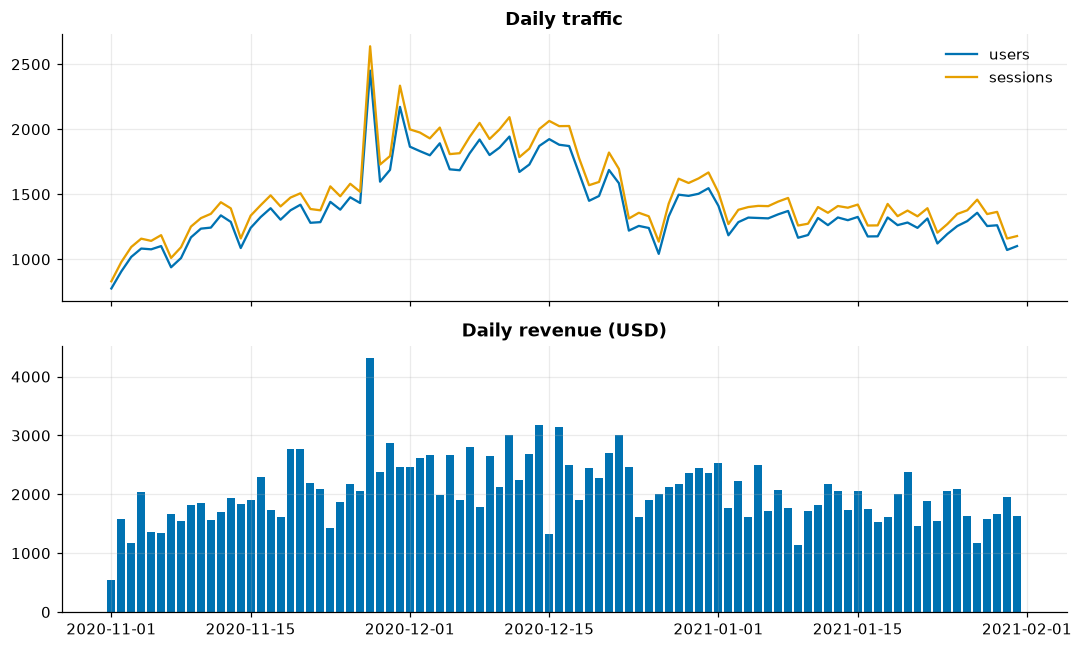

In [8]:
import matplotlib.pyplot as plt

daily = wh.query("SELECT date, users, sessions, transactions, revenue_usd FROM daily_kpis ORDER BY date")
fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
axes[0].plot(daily["date"], daily["users"], label="users")
axes[0].plot(daily["date"], daily["sessions"], label="sessions")
axes[0].set_title("Daily traffic")
axes[0].legend()
axes[1].bar(daily["date"], daily["revenue_usd"], width=0.8)
axes[1].set_title("Daily revenue (USD)")
fig.tight_layout()
save(fig, "01_daily_traffic_revenue")

In [9]:
users = wh.query("""
SELECT first_session_channel AS channel,
       count(*) AS users,
       round(100 * avg(purchased::INT), 2) AS purchaser_pct,
       round(avg(sessions), 2) AS sessions_per_user,
       round(avg(sessions_to_first_purchase), 2) AS sessions_to_first_purchase
FROM users
GROUP BY 1 ORDER BY users DESC
""")
users

dry run OK | local tables: ga4.main.users


,channel,users,purchaser_pct,sessions_per_user,sessions_to_first_purchase
0,Organic Search,23763,5.16,1.74,1.93
1,Paid Search,12678,5.66,1.74,1.78
2,Direct,11718,6.27,1.79,1.72
3,Organic Social,9356,4.09,1.70,2.19
4,Display,9284,3.83,1.69,2.07
5,Referral,7963,4.47,1.72,1.92
6,Affiliates,3087,5.09,1.73,1.85
7,Email,2151,7.86,2.02,1.88


**Takeaways**

- The dry run makes cost visible before anything runs: a one-day, two-column query reads a
  fraction of a percent of what the full flatten reads.
- Sessions convert at about 3% and AOV is about $45; traffic peaks on Black Friday and Cyber
  Monday, and revenue dips over Christmas.
- Purchasers need more than one session on average, so a single-session view of the funnel
  undercounts the role of the channels that bring users back (see notebook 03).